#Are Players Using the White Pieces More Likely to Win Chess Games?

## 1. Dataset
- **Title:** Chess Game Dataset (Lichess)
- **Source:** https://www.kaggle.com/datasets/datasnaek/chess
- **Description:** About 20,000 online chess games played on Lichess (2017). Each row is one game with the players' ratings, the winner, how the game ended, the number of turns, the time control, and the opening played.

## 2. Problem Definition
**Main questions**
1. Does White win more often than Black?
2. Are Players Who Move First More Likely to Win Chess Games?
3. Does a Higher Player Rating Increase the Chances of Winning a Chess Game?
4. Which Chess Openings Are More Likely to Lead to a Win?
5. How does game length change with the way the game ends?

read data set

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
data = pd.read_csv("games.csv")
data.head()

,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.500000e+12,1.500000e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.500000e+12,1.500000e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.500000e+12,1.500000e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
3,kWKvrqYL,True,1.500000e+12,1.500000e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
4,9tXo1AUZ,True,1.500000e+12,1.500000e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5


In [3]:
print(data.shape)

(20058, 16)


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20058 entries, 0 to 20057
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              20058 non-null  object 
 1   rated           20058 non-null  bool   
 2   created_at      20058 non-null  float64
 3   last_move_at    20058 non-null  float64
 4   turns           20058 non-null  int64  
 5   victory_status  20058 non-null  object 
 6   winner          20058 non-null  object 
 7   increment_code  20058 non-null  object 
 8   white_id        20058 non-null  object 
 9   white_rating    20058 non-null  int64  
 10  black_id        20058 non-null  object 
 11  black_rating    20058 non-null  int64  
 12  moves           20058 non-null  object 
 13  opening_eco     20058 non-null  object 
 14  opening_name    20058 non-null  object 
 15  opening_ply     20058 non-null  int64  
dtypes: bool(1), float64(2), int64(4), object(9)
memory usage: 2.3+ MB


In [5]:
data.describe()

,created_at,last_move_at,turns,white_rating,black_rating,opening_ply
count,2.005800e+04,2.005800e+04,20058.000000,20058.000000,20058.000000,20058.000000
mean,1.483208e+12,1.483208e+12,60.465999,1596.631868,1588.831987,4.816981
std,2.831972e+10,2.831967e+10,33.570585,291.253376,291.036126,2.797152
min,1.376770e+12,1.376770e+12,1.000000,784.000000,789.000000,1.000000
25%,1.479640e+12,1.479642e+12,37.000000,1398.000000,1391.000000,3.000000
50%,1.497030e+12,1.497030e+12,55.000000,1567.000000,1562.000000,4.000000
75%,1.500708e+12,1.500708e+12,79.000000,1793.000000,1784.000000,6.000000
max,1.504490e+12,1.504490e+12,349.000000,2700.000000,2723.000000,28.000000


In [6]:
print(data.isna().sum())

id                0
rated             0
created_at        0
last_move_at      0
turns             0
victory_status    0
winner            0
increment_code    0
white_id          0
white_rating      0
black_id          0
black_rating      0
moves             0
opening_eco       0
opening_name      0
opening_ply       0
dtype: int64


In [7]:
print(data.duplicated().sum())

429


In [8]:
print(data.nunique())

id                19113
rated                 2
created_at         2626
last_move_at       2657
turns               211
victory_status        4
winner                3
increment_code      400
white_id           9438
white_rating       1516
black_id           9331
black_rating       1521
moves             18920
opening_eco         365
opening_name       1477
opening_ply          23
dtype: int64


clean data set

In [9]:
print("Number of fully duplicated rows (all columns identical):")
print(data.duplicated().sum())

print("\nNumber of repeated game ids (an id that appears again):")
print(data['id'].duplicated().sum())

dup_ids = data[data['id'].duplicated(keep=False)].sort_values('id')

sample_id = dup_ids['id'].iloc[0]
print("\nAll rows of one repeated game id (" + sample_id + "), flipped so the rows can be compared:")
data[data['id'] == sample_id].T

Number of fully duplicated rows (all columns identical):
429

Number of repeated game ids (an id that appears again):
945

All rows of one repeated game id (061LCiAb), flipped so the rows can be compared:


,10570,11279
id,061LCiAb,061LCiAb
rated,True,True
created_at,1396110000000.0,1396110000000.0
last_move_at,1396110000000.0,1396110000000.0
turns,66,66
victory_status,draw,draw
winner,draw,draw
increment_code,10+15,10+15
white_id,faraon7,faraon7
white_rating,1630,1630


In [10]:
id_dup = data['id'].duplicated(keep=False)
full_dup = data.duplicated(keep=False)

diff_rows = data[id_dup & ~full_dup].sort_values('id')
print("Shape (rows, columns) of rows with a repeated id that are NOT exact duplicates:")
print(diff_rows.shape)

print("\nFirst 10 of these rows (only the timestamps differ):")
diff_rows.head(10)

Shape (rows, columns) of rows with a repeated id that are NOT exact duplicates:
(942, 16)

First 10 of these rows (only the timestamps differ):


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
720,079kHDqh,True,1.500000e+12,1.500000e+12,32,resign,black,10+0,wiggleitjiggleit,1448,penguin_lo,1436,d4 d5 c4 Bf5 Nf3 e6 e3 Nc6 cxd5 Qxd5 Bd3 Bb4+ ...,D02,Queen's Gambit Refused: Baltic Defense,4
12208,079kHDqh,True,1.504110e+12,1.504110e+12,32,resign,black,10+0,wiggleitjiggleit,1448,penguin_lo,1436,d4 d5 c4 Bf5 Nf3 e6 e3 Nc6 cxd5 Qxd5 Bd3 Bb4+ ...,D02,Queen's Gambit Refused: Baltic Defense,4
18642,07e0uVvn,True,1.491950e+12,1.491960e+12,35,mate,white,30+0,chessguy9001,1259,helykopter33,1319,e4 e5 Nf3 Nf6 d3 Bc5 Nxe5 d6 Nc4 Bxf2+ Kxf2 Ng...,C42,Petrov's Defense,4
3882,07e0uVvn,True,1.490000e+12,1.490000e+12,35,mate,white,30+0,chessguy9001,1259,helykopter33,1319,e4 e5 Nf3 Nf6 d3 Bc5 Nxe5 d6 Nc4 Bxf2+ Kxf2 Ng...,C42,Petrov's Defense,4
5413,09fzI0ta,True,1.500000e+12,1.500000e+12,55,resign,white,10+0,artem555,1594,justello99,1608,d4 e6 c4 d5 cxd5 Qxd5 Nc3 Bb4 a3 Bxc3+ bxc3 Nf...,D30,Queen's Gambit Declined,4
18317,09fzI0ta,True,1.500990e+12,1.500990e+12,55,resign,white,10+0,artem555,1594,justello99,1608,d4 e6 c4 d5 cxd5 Qxd5 Nc3 Bb4 a3 Bxc3+ bxc3 Nf...,D30,Queen's Gambit Declined,4
12243,0CCos4zy,True,1.503170e+12,1.503170e+12,62,resign,black,10+0,everest999,1651,saviter,1684,e4 e5 d3 Nc6 Nf3 Nf6 Bg5 h6 Bh4 Be7 Nc3 O-O Be...,C20,King's Pawn Game: Leonardis Variation,3
808,0CCos4zy,True,1.500000e+12,1.500000e+12,62,resign,black,10+0,everest999,1651,saviter,1684,e4 e5 d3 Nc6 Nf3 Nf6 Bg5 h6 Bh4 Be7 Nc3 O-O Be...,C20,King's Pawn Game: Leonardis Variation,3
1149,0LeqFhxc,False,1.500000e+12,1.500000e+12,135,draw,draw,15+5,bekzodjon,1716,bobby70,1763,e4 e6 d4 d6 f4 Nd7 Nf3 h6 e5 d5 Bb5 a6 Ba4 b5 ...,C00,Rat Defense: Small Center Defense,4
14603,0LeqFhxc,False,1.496570e+12,1.496570e+12,135,draw,draw,15+5,bekzodjon,1716,bobby70,1763,e4 e6 d4 d6 f4 Nd7 Nf3 h6 e5 d5 Bb5 a6 Ba4 b5 ...,C00,Rat Defense: Small Center Defense,4


In [11]:
df = data.drop_duplicates(subset='id', keep='first').copy()
print("Shape after removing repeated game ids (rows, columns):")
print(df.shape)

print("\nRepeated ids remaining (expected 0):")
print(df['id'].duplicated().sum())

Shape after removing repeated game ids (rows, columns):
(19113, 16)

Repeated ids remaining (expected 0):
0


In [12]:
# the duplication occurred in two stages 429 rows that were exact matches, and 516 rows representing the same game but with difference in timing

In [13]:
df['created_at'] = pd.to_datetime(df['created_at'], unit='ms')
df['last_move_at'] = pd.to_datetime(df['last_move_at'], unit='ms')
df[['created_at', 'last_move_at']].head()

,created_at,last_move_at
0,2017-07-14 02:40:00,2017-07-14 02:40:00
1,2017-07-14 02:40:00,2017-07-14 02:40:00
2,2017-07-14 02:40:00,2017-07-14 02:40:00
3,2017-07-14 02:40:00,2017-07-14 02:40:00
4,2017-07-14 02:40:00,2017-07-14 02:40:00


In [14]:
df['duration_min'] = (df['last_move_at'] - df['created_at']).dt.total_seconds() / 60

print("Number of games with a duration of exactly 0 minutes:")
print((df['duration_min'] == 0).sum())

print("\nPercentage of games with a duration of 0 minutes:")
print(round((df['duration_min'] == 0).mean() * 100, 1))

print("\nSummary of duration_min (in minutes):")
df['duration_min'].describe()

Number of games with a duration of exactly 0 minutes:
18257

Percentage of games with a duration of 0 minutes:
95.5

Summary of duration_min (in minutes):


,duration_min
count,19113.000000
mean,8.066063
std,81.661702
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,10166.666667


In [15]:
print("Number of games with fewer than 3 turns:")
print((df['turns'] < 3).sum())

print("\nLongest game (maximum number of turns):")
print(df['turns'].max())

print("\nThe 5 longest games (turns, how the game ended, winner):")
df.nlargest(5, 'turns')[['turns', 'victory_status', 'winner']]

Number of games with fewer than 3 turns:
194

Longest game (maximum number of turns):
349

The 5 longest games (turns, how the game ended, winner):


,turns,victory_status,winner
11554,349,outoftime,white
16386,259,draw,draw
4236,255,draw,draw
16645,226,draw,draw
15478,222,draw,draw


In [16]:
short = df[df['turns'] < 3]
print("How the games with fewer than 3 turns ended (victory_status):")
print(short['victory_status'].value_counts())

print("\nAre these short games rated? (rated column):")
print(short['rated'].value_counts())

print("\nFirst 10 of the short games:")
short[['turns', 'victory_status', 'winner', 'rated']].head(10)

How the games with fewer than 3 turns ended (victory_status):
victory_status
resign       152
outoftime     40
draw           2
Name: count, dtype: int64

Are these short games rated? (rated column):
rated
True     153
False     41
Name: count, dtype: int64

First 10 of the short games:


,turns,victory_status,winner,rated
141,2,resign,black,True
439,2,draw,draw,True
460,2,outoftime,black,True
1814,2,outoftime,black,False
1946,1,resign,black,True
1956,2,outoftime,black,True
1961,2,outoftime,black,True
1962,2,resign,black,True
1966,2,resign,black,False
1967,2,resign,white,False


In [17]:
df = df[df['turns'] >= 3].copy()
print("Shape after removing games with fewer than 3 turns (rows, columns):")
print(df.shape)

Shape after removing games with fewer than 3 turns (rows, columns):
(18919, 17)


In [18]:
# Removed 194 games with fewer than 3 turns (about 1% of the data).
# Most of them ended by resignation or timeout, so they do not reflect real play
# and would distort the analysis of game length and openings.
# Shape after removal: (18919, 17)

In [19]:
print("Number of games for each winner (white / black / draw):")
print(df['winner'].value_counts())

print("\nNumber of games for each way of ending (victory_status):")
print(df['victory_status'].value_counts())

print("\nNumber of rated vs. unrated games:")
print(df['rated'].value_counts())

Number of games for each winner (white / black / draw):
winner
white    9459
black    8574
draw      886
Name: count, dtype: int64

Number of games for each way of ending (victory_status):
victory_status
resign       10543
mate          5974
outoftime     1558
draw           844
Name: count, dtype: int64

Number of rated vs. unrated games:
rated
True     15314
False     3605
Name: count, dtype: int64


In [20]:
mismatch = df[(df['winner'] == 'draw') & (df['victory_status'] != 'draw')]
print("Shape (rows, columns) of games where winner = draw but victory_status is not draw:")
print(mismatch.shape)

print("\nHow these games ended (victory_status):")
print(mismatch['victory_status'].value_counts())

print("\nFirst 10 of these games:")
mismatch[['turns', 'victory_status', 'winner', 'rated']].head(10)

Shape (rows, columns) of games where winner = draw but victory_status is not draw:
(42, 17)

How these games ended (victory_status):
victory_status
outoftime    42
Name: count, dtype: int64

First 10 of these games:


,turns,victory_status,winner,rated
176,144,outoftime,draw,False
370,163,outoftime,draw,True
376,89,outoftime,draw,True
433,148,outoftime,draw,True
1152,114,outoftime,draw,False
1220,95,outoftime,draw,True
1812,88,outoftime,draw,True
2219,173,outoftime,draw,True
2252,208,outoftime,draw,True
2279,158,outoftime,draw,True


In [21]:
# 42 games have winner=draw but victory_status=outoftime this is valid in chess when time runs out but the opponent cannot checkmate the game is a draw

Processing

Summary statistics of White and Black ratings:
       white_rating  black_rating
count  18919.000000  18919.000000
mean    1598.869338   1591.645013
std      288.075364    289.044093
min      784.000000    789.000000
25%     1403.500000   1397.000000
50%     1568.000000   1564.000000
75%     1793.000000   1786.000000
max     2700.000000   2621.000000

Boxplot of White and Black ratings:


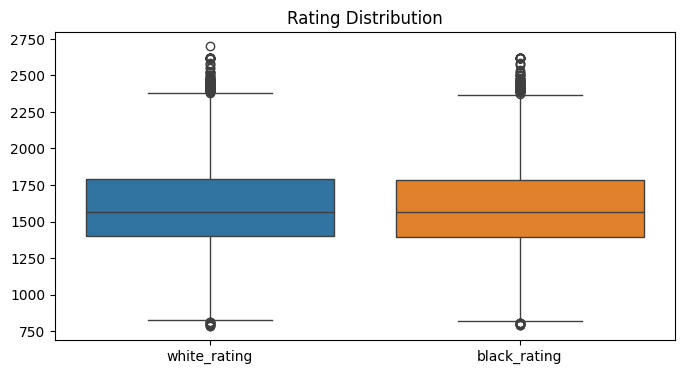

In [22]:
print("Summary statistics of White and Black ratings:")
print(df[['white_rating', 'black_rating']].describe())

print("\nBoxplot of White and Black ratings:")
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[['white_rating', 'black_rating']])
plt.title('Rating Distribution')
plt.show()

In [23]:
df['rating_diff'] = df['white_rating'] - df['black_rating']
print("Summary of rating_diff (White rating minus Black rating):")
df['rating_diff'].describe()

Summary of rating_diff (White rating minus Black rating):


,rating_diff
count,18919.000000
mean,7.224325
std,244.838985
min,-1605.000000
25%,-107.000000
50%,3.000000
75%,121.000000
max,1499.000000


In [24]:
bins = [-np.inf, -200, -50, 0, 50, 200, np.inf]
labels = ['Black much stronger', 'Black stronger', 'Even (Black slightly higher)',
          'Even (White slightly higher)', 'White stronger', 'White much stronger']

df['rating_diff_cat'] = pd.cut(df['rating_diff'], bins=bins, labels=labels)

print("Number of games in each rating-difference category:")
print(df['rating_diff_cat'].value_counts().sort_index())

Number of games in each rating-difference category:
rating_diff_cat
Black much stronger             2824
Black stronger                  3851
Even (Black slightly higher)    2660
Even (White slightly higher)    2477
White stronger                  4059
White much stronger             3048
Name: count, dtype: int64


In [25]:
df['white_win'] = (df['winner'] == 'white').astype(int)

print("Number of games White did not win (0, includes draws) and won (1):")
print(df['white_win'].value_counts())

print("\nShare of all games that White won (0 to 1):")
print(df['white_win'].mean())

Number of games White did not win (0, includes draws) and won (1):
white_win
0    9460
1    9459
Name: count, dtype: int64

Share of all games that White won (0 to 1):
0.49997357154183625


In [26]:
win_rate = df.groupby('rating_diff_cat', observed=True)['white_win'].mean()
print("White win rate in each rating-difference category (0 to 1):")
print(win_rate)

White win rate in each rating-difference category (0 to 1):
rating_diff_cat
Black much stronger             0.211402
Black stronger                  0.378084
Even (Black slightly higher)    0.471053
Even (White slightly higher)    0.505450
White stronger                  0.614437
White much stronger             0.789698
Name: white_win, dtype: float64


In [27]:
even = df[(df['rating_diff'] >= -50) & (df['rating_diff'] <= 50)]

print("Shape (rows, columns) of evenly matched games (rating difference between -50 and +50):")
print(even.shape)

print("\nNumber of White wins, Black wins and draws in these games:")
print(even['winner'].value_counts())

print("\nShare of each result in these games:")
print(even['winner'].value_counts(normalize=True))

Shape (rows, columns) of evenly matched games (rating difference between -50 and +50):
(5178, 20)

Number of White wins, Black wins and draws in these games:
winner
white    2525
black    2377
draw      276
Name: count, dtype: int64

Share of each result in these games:
winner
white    0.487640
black    0.459058
draw     0.053302
Name: proportion, dtype: float64


In [28]:
print("Binomial test on evenly matched games (rating difference between -50 and +50), draws excluded:")
white_wins = (even['winner'] == 'white').sum()
black_wins = (even['winner'] == 'black').sum()
n = white_wins + black_wins
print("White wins:", white_wins, "| Black wins:", black_wins, "| n =", n)

result = stats.binomtest(white_wins, n=n, p=0.5, alternative='two-sided')
print("p-value =", result.pvalue)

Binomial test on evenly matched games (rating difference between -50 and +50), draws excluded:
White wins: 2525 | Black wins: 2377 | n = 4902
p-value = 0.035755834675307005


In [29]:
rows = []
for t in [25, 50, 100]:
    sub = df[df['rating_diff'].abs() <= t]
    w = (sub['winner'] == 'white').sum()
    b = (sub['winner'] == 'black').sum()
    p = stats.binomtest(w, n=w + b, p=0.5, alternative='two-sided').pvalue
    rows.append({'threshold': t, 'games': len(sub), 'white_wins': w,
                 'black_wins': b, 'white_share': w / (w + b), 'p_value': p})

robust = pd.DataFrame(rows)
print("Robustness check: for each definition of 'even' (threshold = maximum rating difference),")
print("the number of games, White and Black wins, White's share of non-drawn games, and the p-value:")
robust

Robustness check: for each definition of 'even' (threshold = maximum rating difference),
the number of games, White and Black wins, White's share of non-drawn games, and the p-value:


,threshold,games,white_wins,black_wins,white_share,p_value
0,25,2982,1470,1353,0.520723,0.029000
1,50,5178,2525,2377,0.515096,0.035756
2,100,8707,4285,3957,0.519898,0.000315


In [30]:
# 1) Split `increment_code` into two columns
parts = df['increment_code'].str.split('+', expand=True)
df['base_min'] = parts[0].astype(int)
df['increment_sec'] = parts[1].astype(int)

# 2) Estimated time (Lichess standard: 40 moves)
df['est_time_sec'] = df['base_min'] * 60 + 40 * df['increment_sec']

# 3) Classification
bins = [-np.inf, 179, 479, 1499, np.inf]
labels = ['Bullet', 'Blitz', 'Rapid', 'Classical']
df['game_type'] = pd.cut(df['est_time_sec'], bins=bins, labels=labels)

print("Number of games in each game type (Bullet / Blitz / Rapid / Classical):")
print(df['game_type'].value_counts().sort_index())

print("\nNumber of games with a missing game type (expected 0):")
print(df['game_type'].isna().sum())

Number of games in each game type (Bullet / Blitz / Rapid / Classical):
game_type
Bullet           0
Blitz            4
Rapid        16104
Classical     2811
Name: count, dtype: int64

Number of games with a missing game type (expected 0):
0


## Chess Time Controls ♟️

Each player has a clock. Your time goes down only on your turn, and if it runs out you usually lose. In `increment_code` such as `15+2`, the first number is the base time in **minutes** and the second is the **seconds added after every move**.

Lichess classifies a game by its **estimated duration**:

`estimated time (seconds) = base minutes x 60 + 40 x increment seconds` (Lichess assumes a game lasts about 40 moves)

| Type | Estimated time |
|---|---|
| Bullet | less than 180 seconds |
| Blitz | 180 to 479 seconds |
| Rapid | 480 to 1499 seconds |
| Classical | 1500 seconds or more |



In [31]:
print("Top 10 most common base times (minutes) and their number of games:")
print(df['base_min'].value_counts().head(10))

Top 10 most common base times (minutes) and their number of games:
base_min
10    8926
15    3199
5     1697
20     896
8      883
30     707
7      599
25     305
9      247
12     218
Name: count, dtype: int64


In [32]:
print("Preview of the dataframe after adding base_min, increment_sec, est_time_sec and game_type:")
df

Preview of the dataframe after adding base_min, increment_sec, est_time_sec and game_type:


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,...,opening_name,opening_ply,duration_min,rating_diff,rating_diff_cat,white_win,base_min,increment_sec,est_time_sec,game_type
0,TZJHLljE,False,2017-07-14 02:40:00,2017-07-14 02:40:00,13,outoftime,white,15+2,bourgris,1500,...,Slav Defense: Exchange Variation,5,0.0,309,White much stronger,1,15,2,980,Rapid
1,l1NXvwaE,True,2017-07-14 02:40:00,2017-07-14 02:40:00,16,resign,black,5+10,a-00,1322,...,Nimzowitsch Defense: Kennedy Variation,4,0.0,61,White stronger,0,5,10,700,Rapid
2,mIICvQHh,True,2017-07-14 02:40:00,2017-07-14 02:40:00,61,mate,white,5+10,ischia,1496,...,King's Pawn Game: Leonardis Variation,3,0.0,-4,Even (Black slightly higher),1,5,10,700,Rapid
3,kWKvrqYL,True,2017-07-14 02:40:00,2017-07-14 02:40:00,61,mate,white,20+0,daniamurashov,1439,...,Queen's Pawn Game: Zukertort Variation,3,0.0,-15,Even (Black slightly higher),1,20,0,1200,Rapid
4,9tXo1AUZ,True,2017-07-14 02:40:00,2017-07-14 02:40:00,95,mate,white,30+3,nik221107,1523,...,Philidor Defense,5,0.0,54,White stronger,1,30,3,1920,Classical
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,EfqH7VVH,True,2017-07-11 16:20:00,2017-07-11 16:20:00,24,resign,white,10+10,belcolt,1691,...,Dutch Defense,2,0.0,471,White much stronger,1,10,10,1000,Rapid
20054,WSJDhbPl,True,2017-07-10 15:20:00,2017-07-10 15:20:00,82,mate,black,10+0,jamboger,1233,...,Queen's Pawn,2,0.0,37,Even (White slightly higher),0,10,0,600,Rapid
20055,yrAas0Kj,True,2017-07-10 15:20:00,2017-07-10 15:20:00,35,mate,white,10+0,jamboger,1219,...,Queen's Pawn Game: Mason Attack,3,0.0,-67,Black stronger,1,10,0,600,Rapid
20056,b0v4tRyF,True,2017-07-10 15:20:00,2017-07-10 15:20:00,109,resign,white,10+0,marcodisogno,1360,...,Pirc Defense,4,0.0,133,White stronger,1,10,0,600,Rapid


In [33]:
# Descriptive time groups based on base time (minutes)
bins = [-np.inf, 9, 10, np.inf]
labels = ['Short (<10 min)', 'Medium (10 min)', 'Long (>10 min)']
df['time_group'] = pd.cut(df['base_min'], bins=bins, labels=labels)

print("Number of games in each time group (Short / Medium / Long):")
print(df['time_group'].value_counts().sort_index())

print("\nNumber of games with a missing time group (expected 0):")
print(df['time_group'].isna().sum())

print("\nNumber of games with base time of exactly 10 minutes (expected 8926):")
print((df['base_min'] == 10).sum())

Number of games in each time group (Short / Medium / Long):
time_group
Short (<10 min)    3830
Medium (10 min)    8926
Long (>10 min)     6163
Name: count, dtype: int64

Number of games with a missing time group (expected 0):
0

Number of games with base time of exactly 10 minutes (expected 8926):
8926


Created `time_group` from `base_min` (base time in minutes) with 3 descriptive groups:

 Short (<10 min), Medium (10 min), Long (>10 min).


 Because Lichess standard (`game_type`) gave Bullet = 0 and Blitz = 4 games only,so it is kept for reference, while `time_group` is used for the charts and dashboard.

In [34]:
# Average rating of the two players in each game
df['avg_rating'] = (df['white_rating'] + df['black_rating']) / 2

# Skill level groups (cut points at the 1st and 3rd quartiles: ~1400 and ~1790)
bins = [-np.inf, 1400, 1790, np.inf]
labels = ['Beginner (<=1400)', 'Intermediate (1400-1790)', 'Advanced (>1790)']
df['skill_level'] = pd.cut(df['avg_rating'], bins=bins, labels=labels)

print("Number of games in each skill level (Beginner / Intermediate / Advanced):")
print(df['skill_level'].value_counts().sort_index())

print("\nNumber of games with a missing skill level (expected 0):")
print(df['skill_level'].isna().sum())

print("\nSummary of the average rating (min, median, max):")
print(df['avg_rating'].describe())

Number of games in each skill level (Beginner / Intermediate / Advanced):
skill_level
Beginner (<=1400)            4443
Intermediate (1400-1790)    10070
Advanced (>1790)             4406
Name: count, dtype: int64

Number of games with a missing skill level (expected 0):
0

Summary of the average rating (min, median, max):
count    18919.000000
mean      1595.257175
std        261.305223
min        827.000000
25%       1411.500000
50%       1571.000000
75%       1773.000000
max       2475.500000
Name: avg_rating, dtype: float64


**Skill level:** the cut points (1400 and 1790) are close to the 1st and 3rd quartiles of `avg_rating` (1411 and 1773). Result: Beginner 4,443, Intermediate 10,070, Advanced 4,406 games.

In [35]:
df

,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,...,rating_diff,rating_diff_cat,white_win,base_min,increment_sec,est_time_sec,game_type,time_group,avg_rating,skill_level
0,TZJHLljE,False,2017-07-14 02:40:00,2017-07-14 02:40:00,13,outoftime,white,15+2,bourgris,1500,...,309,White much stronger,1,15,2,980,Rapid,Long (>10 min),1345.5,Beginner (<=1400)
1,l1NXvwaE,True,2017-07-14 02:40:00,2017-07-14 02:40:00,16,resign,black,5+10,a-00,1322,...,61,White stronger,0,5,10,700,Rapid,Short (<10 min),1291.5,Beginner (<=1400)
2,mIICvQHh,True,2017-07-14 02:40:00,2017-07-14 02:40:00,61,mate,white,5+10,ischia,1496,...,-4,Even (Black slightly higher),1,5,10,700,Rapid,Short (<10 min),1498.0,Intermediate (1400-1790)
3,kWKvrqYL,True,2017-07-14 02:40:00,2017-07-14 02:40:00,61,mate,white,20+0,daniamurashov,1439,...,-15,Even (Black slightly higher),1,20,0,1200,Rapid,Long (>10 min),1446.5,Intermediate (1400-1790)
4,9tXo1AUZ,True,2017-07-14 02:40:00,2017-07-14 02:40:00,95,mate,white,30+3,nik221107,1523,...,54,White stronger,1,30,3,1920,Classical,Long (>10 min),1496.0,Intermediate (1400-1790)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,EfqH7VVH,True,2017-07-11 16:20:00,2017-07-11 16:20:00,24,resign,white,10+10,belcolt,1691,...,471,White much stronger,1,10,10,1000,Rapid,Medium (10 min),1455.5,Intermediate (1400-1790)
20054,WSJDhbPl,True,2017-07-10 15:20:00,2017-07-10 15:20:00,82,mate,black,10+0,jamboger,1233,...,37,Even (White slightly higher),0,10,0,600,Rapid,Medium (10 min),1214.5,Beginner (<=1400)
20055,yrAas0Kj,True,2017-07-10 15:20:00,2017-07-10 15:20:00,35,mate,white,10+0,jamboger,1219,...,-67,Black stronger,1,10,0,600,Rapid,Medium (10 min),1252.5,Beginner (<=1400)
20056,b0v4tRyF,True,2017-07-10 15:20:00,2017-07-10 15:20:00,109,resign,white,10+0,marcodisogno,1360,...,133,White stronger,1,10,0,600,Rapid,Medium (10 min),1293.5,Beginner (<=1400)


In [36]:
# 1) Main opening family = text before ":" (e.g. "Slav Defense: Exchange Variation" -> "Slav Defense")
df['opening_family'] = df['opening_name'].str.split(':').str[0].str.strip()

print("Number of unique opening names BEFORE grouping:")
print(df['opening_name'].nunique())

print("\nNumber of unique opening families AFTER grouping:")
print(df['opening_family'].nunique())

print("\nTop 15 opening families and their number of games:")
print(df['opening_family'].value_counts().head(15))

# 2) Keep the 10 most common families, group the rest as "Other" (for cleaner charts)
top10 = df['opening_family'].value_counts().head(10).index
df['opening_top'] = df['opening_family'].where(df['opening_family'].isin(top10), 'Other')

print("\nNumber of games in each group (top 10 families + Other):")
print(df['opening_top'].value_counts())

print("\nNumber of games with a missing opening family (expected 0):")
print(df['opening_family'].isna().sum())

Number of unique opening names BEFORE grouping:
1476

Number of unique opening families AFTER grouping:
227

Top 15 opening families and their number of games:
opening_family
Sicilian Defense           2464
French Defense             1258
Queen's Pawn Game           995
Italian Game                926
King's Pawn Game            845
Ruy Lopez                   812
English Opening             697
Scandinavian Defense        667
Caro-Kann Defense           558
Scotch Game                 441
Queen's Gambit Declined     377
Four Knights Game           344
Van't Kruijs Opening        320
Indian Game                 311
Bishop's Opening            310
Name: count, dtype: int64

Number of games in each group (top 10 families + Other):
opening_top
Other                   9256
Sicilian Defense        2464
French Defense          1258
Queen's Pawn Game        995
Italian Game             926
King's Pawn Game         845
Ruy Lopez                812
English Opening          697
Scandinavian Defe

**Opening families:** 1,476 opening names were reduced to 227 families by taking the text before ":". The top 10 families are kept and the rest are grouped as `Other` (9,256 games, 49% of the data). `Other` mixes 217 different families, so it is excluded from the opening charts.

Number of games in the top 10 opening families (Other excluded):
9663

White win rate (draws counted as not a White win) and games per opening family:
                      white_win_rate  games
opening_top                                
Sicilian Defense            0.455763   2464
Queen's Pawn Game           0.478392    995
French Defense              0.489666   1258
Italian Game                0.490281    926
Caro-Kann Defense           0.492832    558
Scandinavian Defense        0.496252    667
King's Pawn Game            0.497041    845
Ruy Lopez                   0.520936    812
Scotch Game                 0.541950    441
English Opening             0.552367    697


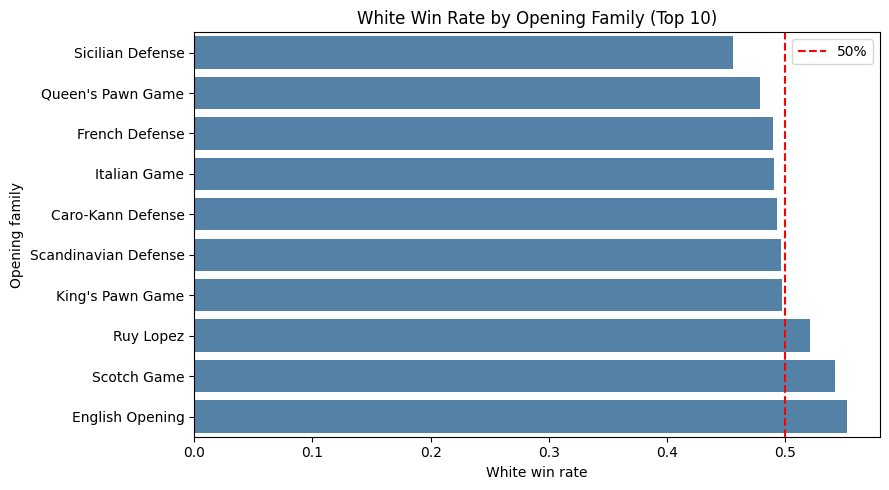

In [37]:
# Keep only the top 10 opening families (exclude "Other")
top_games = df[df['opening_top'] != 'Other']

print("Number of games in the top 10 opening families (Other excluded):")
print(len(top_games))

# White win rate and number of games per opening family
opening_stats = (top_games.groupby('opening_top')['white_win']
                 .agg(['mean', 'count'])
                 .sort_values('mean'))
opening_stats.columns = ['white_win_rate', 'games']

print("\nWhite win rate (draws counted as not a White win) and games per opening family:")
print(opening_stats)

# Bar chart
plt.figure(figsize=(9, 5))
sns.barplot(x=opening_stats['white_win_rate'], y=opening_stats.index, color='steelblue')
plt.axvline(0.5, color='red', linestyle='--', label='50%')
plt.title('White Win Rate by Opening Family (Top 10)')
plt.xlabel('White win rate')
plt.ylabel('Opening family')
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
# Average player rating per opening family (top 10, Other excluded)
rating_by_opening = (top_games.groupby('opening_top')['avg_rating']
                     .agg(['mean', 'count'])
                     .sort_values('mean'))
rating_by_opening.columns = ['avg_rating_mean', 'games']

print("Average player rating (mean of White and Black ratings) and number of games per opening family:")
print(rating_by_opening.round(1))

print("\nOverall average rating of all games, for comparison:")
print(round(df['avg_rating'].mean(), 1))

Average player rating (mean of White and Black ratings) and number of games per opening family:
                      avg_rating_mean  games
opening_top                                 
King's Pawn Game               1407.8    845
Scandinavian Defense           1538.8    667
Scotch Game                    1581.6    441
Italian Game                   1587.7    926
Queen's Pawn Game              1598.5    995
English Opening                1625.8    697
French Defense                 1628.2   1258
Ruy Lopez                      1634.0    812
Caro-Kann Defense              1666.3    558
Sicilian Defense               1675.0   2464

Overall average rating of all games, for comparison:
1595.3


In [39]:
# Save the final cleaned dataset (used by the Streamlit dashboard)
df.to_csv("clean_data.csv", index=False)

# Read it back to check that nothing was lost
check = pd.read_csv("clean_data.csv")

print("Shape of the saved file (expected: 18919 rows):")
print(check.shape)

print("\nColumn names and data types after reading the file back:")
print(check.dtypes)

Shape of the saved file (expected: 18919 rows):
(18919, 29)

Column names and data types after reading the file back:
id                  object
rated                 bool
created_at          object
last_move_at        object
turns                int64
victory_status      object
winner              object
increment_code      object
white_id            object
white_rating         int64
black_id            object
black_rating         int64
moves               object
opening_eco         object
opening_name        object
opening_ply          int64
duration_min       float64
rating_diff          int64
rating_diff_cat     object
white_win            int64
base_min             int64
increment_sec        int64
est_time_sec         int64
game_type           object
time_group          object
avg_rating         float64
skill_level         object
opening_family      object
opening_top         object
dtype: object


Number of games for each result (white / black / draw):
winner
white    9459
black    8574
draw      886
Name: count, dtype: int64

Percentage of games for each result:
winner
white    50.0
black    45.3
draw      4.7
Name: proportion, dtype: float64


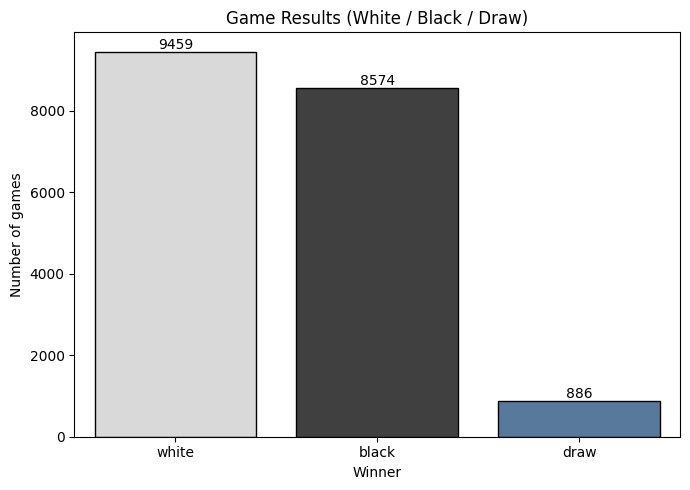

In [40]:
# Number and percentage of games for each result
print("Number of games for each result (white / black / draw):")
print(df['winner'].value_counts())

print("\nPercentage of games for each result:")
print((df['winner'].value_counts(normalize=True) * 100).round(1))

# Countplot
order = ['white', 'black', 'draw']

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='winner', order=order,
                   hue='winner', hue_order=order,
                   palette={'white': '#d9d9d9', 'black': '#404040', 'draw': '#4c78a8'},
                   edgecolor='black', legend=False)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Game Results (White / Black / Draw)')
plt.xlabel('Winner')
plt.ylabel('Number of games')
plt.tight_layout()
plt.show()

Summary of turns (number of moves per game): count, mean, median (50%), min, max:
count    18919.0
mean        61.1
std         33.1
min          3.0
25%         38.0
50%         56.0
75%         79.0
max        349.0
Name: turns, dtype: float64

Number of games with more than 150 turns (very long games):
278


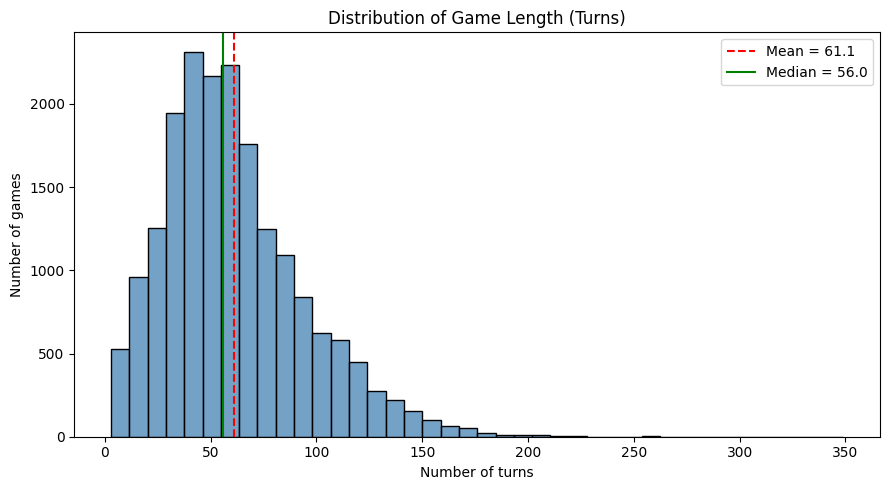

In [41]:
# Summary of the number of turns per game
print("Summary of turns (number of moves per game): count, mean, median (50%), min, max:")
print(df['turns'].describe().round(1))

print("\nNumber of games with more than 150 turns (very long games):")
print((df['turns'] > 150).sum())

# Histogram
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='turns', bins=40, color='steelblue', edgecolor='black')

plt.axvline(df['turns'].mean(), color='red', linestyle='--',
            label=f"Mean = {df['turns'].mean():.1f}")
plt.axvline(df['turns'].median(), color='green', linestyle='-',
            label=f"Median = {df['turns'].median():.1f}")

plt.title('Distribution of Game Length (Turns)')
plt.xlabel('Number of turns')
plt.ylabel('Number of games')
plt.legend()
plt.tight_layout()
plt.show()

Number of games, mean, median (50%), min and max of turns for each victory status:
                  count  mean   std  min   25%   50%    75%    max
victory_status                                                    
draw              844.0  84.9  45.4  3.0  48.8  88.0  115.0  259.0
mate             5974.0  65.6  33.2  4.0  42.0  59.0   83.0  222.0
outoftime        1558.0  74.8  37.4  3.0  51.0  73.0   96.0  349.0
resign          10543.0  54.7  29.1  3.0  34.0  51.0   71.0  218.0


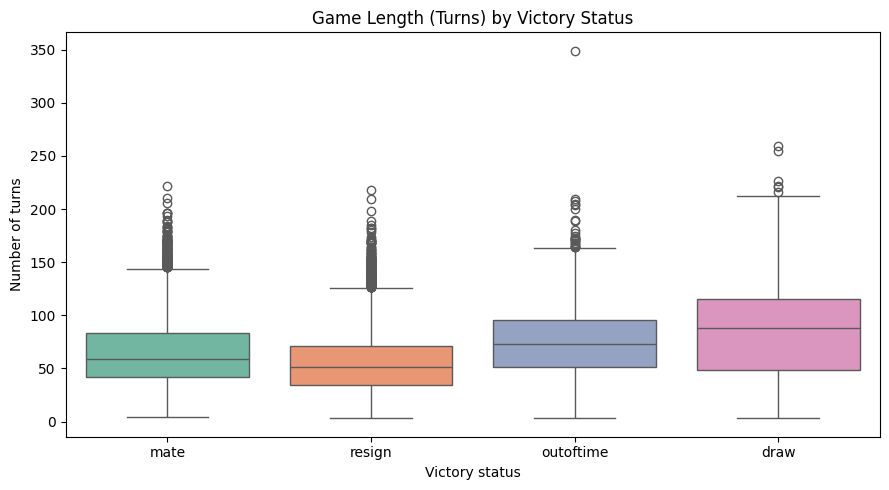

In [42]:
# Summary of turns for each victory status
print("Number of games, mean, median (50%), min and max of turns for each victory status:")
print(df.groupby('victory_status')['turns'].describe().round(1))

# Boxplot
order = ['mate', 'resign', 'outoftime', 'draw']

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='victory_status', y='turns', order=order,
            hue='victory_status', hue_order=order, legend=False,
            palette='Set2')

plt.title('Game Length (Turns) by Victory Status')
plt.xlabel('Victory status')
plt.ylabel('Number of turns')
plt.tight_layout()
plt.show()

Correlation between white_rating and black_rating:
0.64


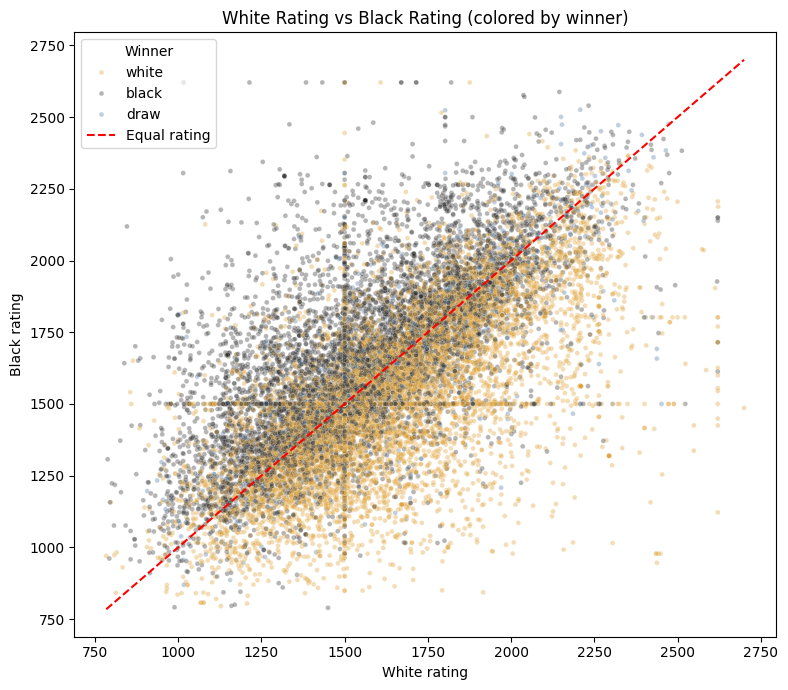

In [43]:
# Correlation between White and Black ratings
corr = df['white_rating'].corr(df['black_rating'])
print("Correlation between white_rating and black_rating:")
print(round(corr, 3))

# Scatter plot colored by winner
order = ['white', 'black', 'draw']
colors = {'white': '#e0a030', 'black': '#2b2b2b', 'draw': '#4c78a8'}

plt.figure(figsize=(8, 7))
sns.scatterplot(data=df, x='white_rating', y='black_rating',
                hue='winner', hue_order=order, palette=colors,
                alpha=0.35, s=12)

# Diagonal line: both players have equal rating
lims = [df[['white_rating', 'black_rating']].min().min(),
        df[['white_rating', 'black_rating']].max().max()]
plt.plot(lims, lims, color='red', linestyle='--', label='Equal rating')

plt.title('White Rating vs Black Rating (colored by winner)')
plt.xlabel('White rating')
plt.ylabel('Black rating')
plt.legend(title='Winner')
plt.tight_layout()
plt.show()

Correlation matrix between the numeric columns (values from -1 to 1):
              turns  white_rating  black_rating  rating_diff  avg_rating  \
turns          1.00          0.13          0.15        -0.03        0.15   
white_rating   0.13          1.00          0.64         0.42        0.91   
black_rating   0.15          0.64          1.00        -0.43        0.91   
rating_diff   -0.03          0.42         -0.43         1.00       -0.00   
avg_rating     0.15          0.91          0.91        -0.00        1.00   
white_win     -0.09          0.13         -0.17         0.35       -0.02   
est_time_sec  -0.05         -0.05         -0.06         0.02       -0.06   

              white_win  est_time_sec  
turns             -0.09         -0.05  
white_rating       0.13         -0.05  
black_rating      -0.17         -0.06  
rating_diff        0.35          0.02  
avg_rating        -0.02         -0.06  
white_win          1.00          0.00  
est_time_sec       0.00          1.00  



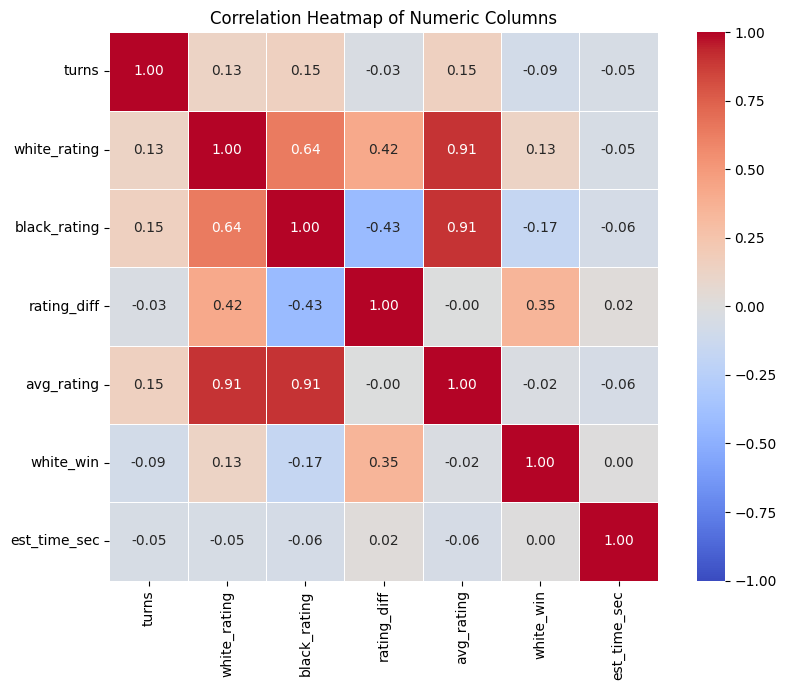

In [44]:
# Numeric columns used in the correlation heatmap
num_cols = ['turns', 'white_rating', 'black_rating', 'rating_diff',
            'avg_rating', 'white_win', 'est_time_sec']

corr_matrix = df[num_cols].corr()

print("Correlation matrix between the numeric columns (values from -1 to 1):")
print(corr_matrix.round(2))

print("\nCorrelation of each column with white_win (sorted):")
print(corr_matrix['white_win'].drop('white_win').sort_values(ascending=False).round(2))

# Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=0.5, square=True)

plt.title('Correlation Heatmap of Numeric Columns')
plt.tight_layout()
plt.show()

Number of games where both players have exactly the same rating (excluded):
196

Number of games used in this analysis:
18723

Overall share of each result (higher-rated player's point of view):
higher_rated_result
Higher-rated won    62.1
Lower-rated won     33.2
Draw                 4.7
Name: proportion, dtype: float64

Number of games in each rating-gap group:
gap_group
1-50       4982
51-100     3529
101-200    4357
201-400    3920
>400       1935
Name: count, dtype: int64

Percentage of each result in each rating-gap group:
higher_rated_result  Higher-rated won  Draw  Lower-rated won
gap_group                                                   
1-50                             49.0   5.3             45.7
51-100                           55.7   5.4             38.9
101-200                          62.0   4.7             33.2
201-400                          74.3   3.9             21.9
>400                             83.1   3.3             13.6


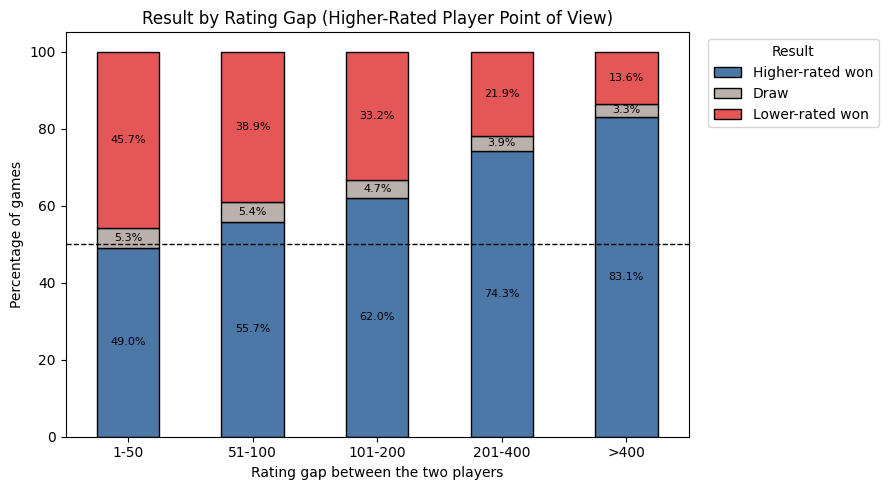

In [45]:
# Games with exactly equal ratings have no "higher-rated" player, so they are excluded
print("Number of games where both players have exactly the same rating (excluded):")
print((df['rating_diff'] == 0).sum())

rated_games = df[df['rating_diff'] != 0].copy()

# Result from the point of view of the higher-rated player
higher_is_white = rated_games['rating_diff'] > 0
rated_games['higher_rated_result'] = np.select(
    [rated_games['winner'] == 'draw',
     (rated_games['winner'] == 'white') == higher_is_white],
    ['Draw', 'Higher-rated won'],
    default='Lower-rated won')

# Group games by the size of the rating gap
rated_games['abs_diff'] = rated_games['rating_diff'].abs()
bins = [0, 50, 100, 200, 400, np.inf]
labels = ['1-50', '51-100', '101-200', '201-400', '>400']
rated_games['gap_group'] = pd.cut(rated_games['abs_diff'], bins=bins, labels=labels)

print("\nNumber of games used in this analysis:")
print(len(rated_games))

print("\nOverall share of each result (higher-rated player's point of view):")
print((rated_games['higher_rated_result'].value_counts(normalize=True) * 100).round(1))

print("\nNumber of games in each rating-gap group:")
print(rated_games['gap_group'].value_counts().sort_index())

rates = pd.crosstab(rated_games['gap_group'], rated_games['higher_rated_result'], normalize='index') * 100
rates = rates[['Higher-rated won', 'Draw', 'Lower-rated won']]

print("\nPercentage of each result in each rating-gap group:")
print(rates.round(1))

# Stacked 100% bar chart
ax = rates.plot(kind='bar', stacked=True, figsize=(9, 5),
                color=['#4c78a8', '#bab0ac', '#e45756'], edgecolor='black')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', fontsize=8)

plt.axhline(50, color='black', linestyle='--', linewidth=1)
plt.title('Result by Rating Gap (Higher-Rated Player Point of View)')
plt.xlabel('Rating gap between the two players')
plt.ylabel('Percentage of games')
plt.xticks(rotation=0)
plt.legend(title='Result', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [46]:
#As the rating gap increases, the higher-rated player wins more often (49.0% to 83.1%), while draws remain rare (3%-5%).
#Players with a 1-50 rating gap are nearly evenly matched. Equal-rating games (196) were excluded, and piece color was not considered.

Number of games in each skill level:
skill_level
Beginner (<=1400)            4443
Intermediate (1400-1790)    10070
Advanced (>1790)             4406
Name: count, dtype: int64

Number of games for each way of ending (victory_status) in each skill level:
victory_status            draw  mate  outoftime  resign
skill_level                                            
Beginner (<=1400)          167  1852        338    2086
Intermediate (1400-1790)   417  3240        823    5590
Advanced (>1790)           260   882        397    2867

Percentage of each way of ending in each skill level (each row = 100%):
victory_status            mate  resign  outoftime  draw
skill_level                                            
Beginner (<=1400)         41.7    47.0        7.6   3.8
Intermediate (1400-1790)  32.2    55.5        8.2   4.1
Advanced (>1790)          20.0    65.1        9.0   5.9


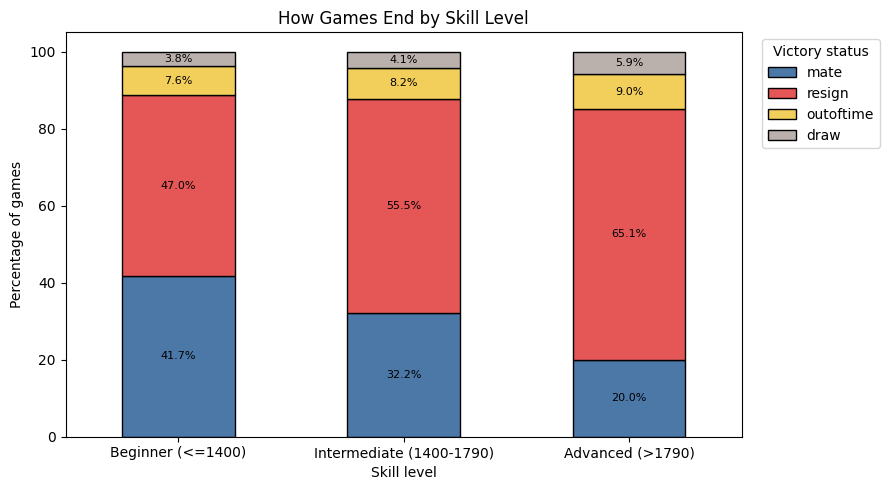

In [47]:
# Number of games in each skill level
print("Number of games in each skill level:")
print(df['skill_level'].value_counts().sort_index())

# Number of games for each way of ending, per skill level
print("\nNumber of games for each way of ending (victory_status) in each skill level:")
print(pd.crosstab(df['skill_level'], df['victory_status']))

# Percentage of each ending inside each skill level (each row adds up to 100%)
status_order = ['mate', 'resign', 'outoftime', 'draw']
status_rates = pd.crosstab(df['skill_level'], df['victory_status'], normalize='index') * 100
status_rates = status_rates[status_order]

print("\nPercentage of each way of ending in each skill level (each row = 100%):")
print(status_rates.round(1))

# Stacked 100% bar chart
ax = status_rates.plot(kind='bar', stacked=True, figsize=(9, 5),
                       color=['#4c78a8', '#e45756', '#f2cf5b', '#bab0ac'],
                       edgecolor='black')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', fontsize=8)

plt.title('How Games End by Skill Level')
plt.xlabel('Skill level')
plt.ylabel('Percentage of games')
plt.xticks(rotation=0)
plt.legend(title='Victory status', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Number of games, mean, median (50%), quartiles, min and max of turns in each skill level:
                            count  mean   std  min   25%   50%   75%    max
skill_level                                                                
Beginner (<=1400)          4443.0  53.9  31.6  3.0  31.0  49.0  71.0  209.0
Intermediate (1400-1790)  10070.0  61.3  32.7  3.0  38.0  56.0  79.0  259.0
Advanced (>1790)           4406.0  67.9  34.2  3.0  43.0  62.0  86.0  349.0

Median number of turns in each skill level:
skill_level
Beginner (<=1400)           49.0
Intermediate (1400-1790)    56.0
Advanced (>1790)            62.0
Name: turns, dtype: float64


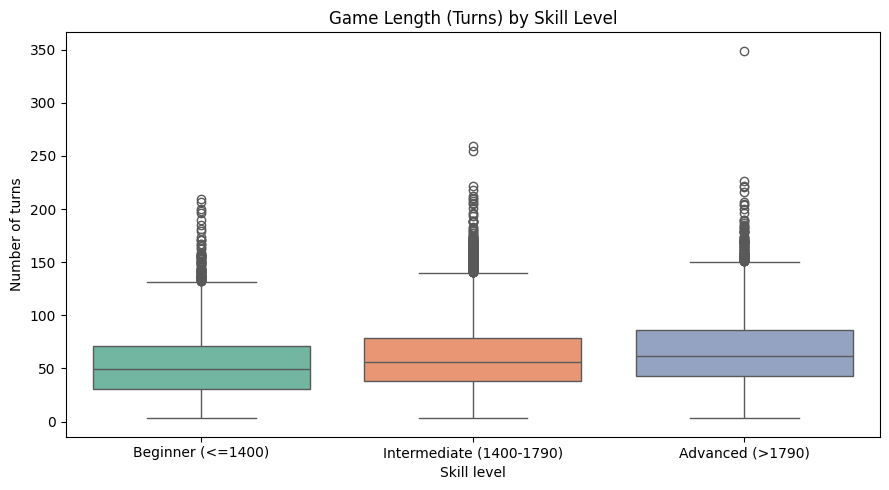

In [48]:
# Summary of turns for each skill level
skill_order = ['Beginner (<=1400)', 'Intermediate (1400-1790)', 'Advanced (>1790)']

print("Number of games, mean, median (50%), quartiles, min and max of turns in each skill level:")
print(df.groupby('skill_level', observed=True)['turns'].describe().round(1))

print("\nMedian number of turns in each skill level:")
print(df.groupby('skill_level', observed=True)['turns'].median())

# Boxplot
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='skill_level', y='turns', order=skill_order,
            hue='skill_level', hue_order=skill_order, legend=False,
            palette='Set2')

plt.title('Game Length (Turns) by Skill Level')
plt.xlabel('Skill level')
plt.ylabel('Number of turns')
plt.tight_layout()
plt.show()

Number of games from the top 10 opening families in each skill level:
skill_level
Beginner (<=1400)           2066
Intermediate (1400-1790)    5235
Advanced (>1790)            2362
Name: count, dtype: int64

Number of games for each opening family in each skill level:
skill_level           Beginner (<=1400)  Intermediate (1400-1790)  \
opening_top                                                         
Caro-Kann Defense                    89                       291   
English Opening                     122                       390   
French Defense                      251                       649   
Italian Game                        180                       591   
King's Pawn Game                    418                       405   
Queen's Pawn Game                   228                       526   
Ruy Lopez                           150                       446   
Scandinavian Defense                225                       311   
Scotch Game                          88  

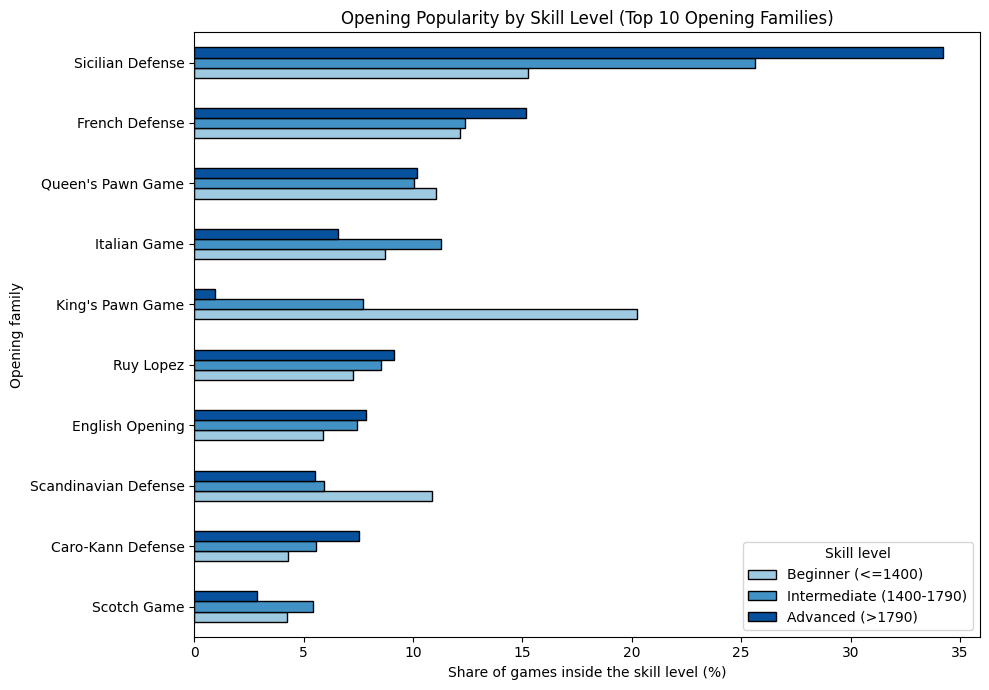

In [49]:
skill_order = ['Beginner (<=1400)', 'Intermediate (1400-1790)', 'Advanced (>1790)']

# Only the top 10 opening families (Other excluded)
top_games = df[df['opening_top'] != 'Other']

print("Number of games from the top 10 opening families in each skill level:")
print(top_games['skill_level'].value_counts().sort_index())

# Number of games for each opening family in each skill level
counts = pd.crosstab(top_games['opening_top'], top_games['skill_level'])[skill_order]
print("\nNumber of games for each opening family in each skill level:")
print(counts)

# Share of each opening inside its skill level (each skill-level column adds up to 100%)
shares = pd.crosstab(top_games['opening_top'], top_games['skill_level'],
                     normalize='columns')[skill_order] * 100

# Order the openings from most to least used overall
opening_order = top_games['opening_top'].value_counts().index
shares = shares.loc[opening_order]

print("\nPercentage of each opening within each skill level (each column = 100%):")
print(shares.round(1))

# Biggest differences between Advanced and Beginner players
diff = (shares[skill_order[2]] - shares[skill_order[0]]).sort_values()
print("\nDifference in usage (Advanced minus Beginner, in percentage points), sorted:")
print(diff.round(1))

# Grouped bar chart
ax = shares.iloc[::-1].plot(kind='barh', figsize=(10, 7),
                            color=['#9ecae1', '#4292c6', '#08519c'],
                            edgecolor='black')

plt.title('Opening Popularity by Skill Level (Top 10 Opening Families)')
plt.xlabel('Share of games inside the skill level (%)')
plt.ylabel('Opening family')
plt.legend(title='Skill level')
plt.tight_layout()
plt.show()

Number of games in each skill level:
skill_level
Beginner (<=1400)            4443
Intermediate (1400-1790)    10070
Advanced (>1790)             4406
Name: count, dtype: int64

Number of games for each result (white / black / draw) in each skill level:
winner                    white  black  draw
skill_level                                 
Beginner (<=1400)          2294   1973   176
Intermediate (1400-1790)   5040   4591   439
Advanced (>1790)           2125   2010   271

Percentage of each result in each skill level (each row = 100%):
winner                    white  black  draw
skill_level                                 
Beginner (<=1400)          51.6   44.4   4.0
Intermediate (1400-1790)   50.0   45.6   4.4
Advanced (>1790)           48.2   45.6   6.2

White win rate minus Black win rate in each skill level (percentage points):
skill_level
Beginner (<=1400)           7.2
Intermediate (1400-1790)    4.5
Advanced (>1790)            2.6
dtype: float64


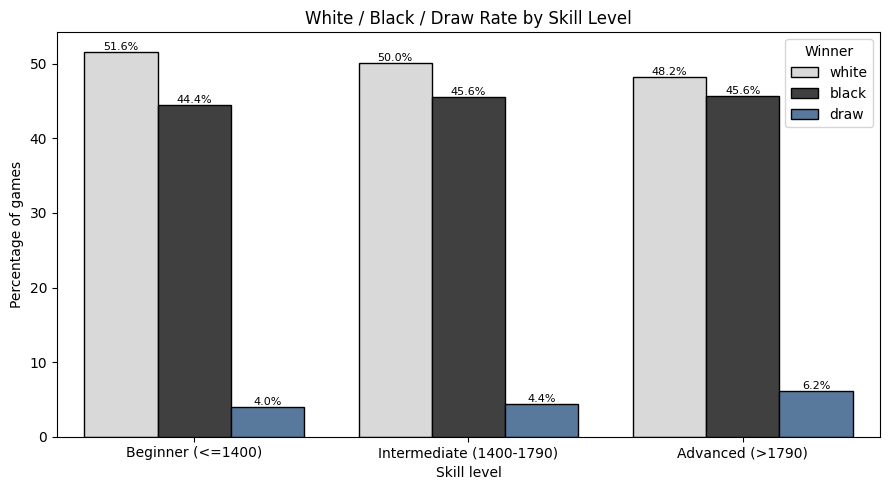

In [50]:
skill_order = ['Beginner (<=1400)', 'Intermediate (1400-1790)', 'Advanced (>1790)']
result_order = ['white', 'black', 'draw']

print("Number of games in each skill level:")
print(df['skill_level'].value_counts().sort_index())

# Number of games for each result in each skill level
print("\nNumber of games for each result (white / black / draw) in each skill level:")
print(pd.crosstab(df['skill_level'], df['winner'])[result_order])

# Percentage of each result inside each skill level (each row = 100%)
result_rates = pd.crosstab(df['skill_level'], df['winner'], normalize='index')[result_order] * 100

print("\nPercentage of each result in each skill level (each row = 100%):")
print(result_rates.round(1))

print("\nWhite win rate minus Black win rate in each skill level (percentage points):")
print((result_rates['white'] - result_rates['black']).round(1))

# Grouped bar chart
plot_data = result_rates.reset_index().melt(id_vars='skill_level',
                                            var_name='winner', value_name='percentage')

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=plot_data, x='skill_level', y='percentage',
                 order=skill_order, hue='winner', hue_order=result_order,
                 palette={'white': '#d9d9d9', 'black': '#404040', 'draw': '#4c78a8'},
                 edgecolor='black')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', fontsize=8)

plt.title('White / Black / Draw Rate by Skill Level')
plt.xlabel('Skill level')
plt.ylabel('Percentage of games')
plt.legend(title='Winner')
plt.tight_layout()
plt.show()

                skill_level Winner  Win Rate (%)
0         Beginner (<=1400)  black     47.297297
1  Intermediate (1400-1790)  black     48.467967
2          Advanced (>1790)  black     49.798793
3         Beginner (<=1400)  white     52.702703
4  Intermediate (1400-1790)  white     51.532033
5          Advanced (>1790)  white     50.201207


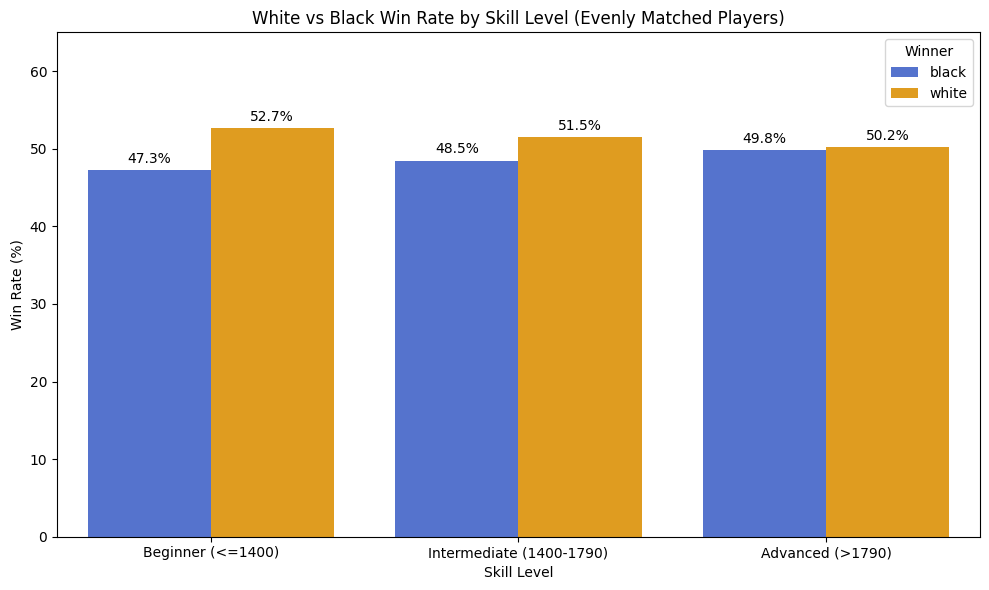

In [52]:
# White vs Black Win Rate by Skill Level (Evenly Matched Players)

# 1. Filter evenly matched games
even_games = df[
    (df['rating_diff'].abs() <= 50) &
    (df['winner'].isin(['white', 'black']))
].copy()

# 2. Calculate win rates
win_rates = pd.crosstab(
    even_games['skill_level'],
    even_games['winner'],
    normalize='index'
) * 100

# 3. Reshape for plotting
win_rates = win_rates.reset_index().melt(
    id_vars='skill_level',
    var_name='Winner',
    value_name='Win Rate (%)'
)

# 4. Check the results
print(win_rates)

# 5. Create the plot
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=win_rates,
    x='skill_level',
    y='Win Rate (%)',
    hue='Winner',
    palette=['royalblue', 'orange']
)

# 6. Add labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('White vs Black Win Rate by Skill Level (Evenly Matched Players)')
plt.xlabel('Skill Level')
plt.ylabel('Win Rate (%)')
plt.ylim(0, 65)
plt.legend(title='Winner')
plt.tight_layout()
plt.show()

##Insights Summary

Game Results
- White won 50.0% of games vs. 45.3% for Black (4.7% draws).

- A white advantage exists among evenly matched games; White won 51.5% of non-drawn games. The effect is possible because White moves first.

- Skill and the White advantage: White wins more than Black at every skill level, but the gap looks smaller for stronger players.


Game Duration & Endings

- Draws are the longest, and resignations the shortest.

- Resignation is the most common ending (10,543 games), followed by mate (5,974), while 2,402 games ended in a draw or by timeout.

- Experienced players often give up when they see their position is lost—even before reaching checkmate—whereas beginners are more likely to play until the very end.

- Checkmate endings decrease from 41.7% among beginners to 20.0% among advanced players, while resignation endings increase from 47.0% to 65.1%.

- Advanced games tend to last longer than beginner games.


Openings

- Openings: English Opening has the highest White win rate (55.2%), and Sicilian Defense the lowest (45.6%).

- Skill and openings: The Sicilian Defense is much more common among advanced players (34.2%) than beginners (15.2%), which fits its high average rating (1675) and low White win rate (45.6%). The King's Pawn Game is mostly a beginner opening (20.2% vs. 0.9%).beginner opening (20.2% vs. 0.9%).